# Vectors, Matrices and Rates: Nielsen & Chuang Chapters 7 and 10 in SymPy

**Colin Casey, 2026.** A companion to M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information* [1]: **Chapter 7, physical realization** (§7.2–7.5) and **Chapter 10, quantum error-correction** (§10.1–10.6). It follows the outline

```python
try:    vectors in these chapters, relating rates
except: neural networks for measurements
```

| Section | Book | Question |
|---|---|---|
| 1. Qubits as vectors in hardware | §7.2, 7.4 | How does a photon carry a qubit, and why is a beamsplitter a rotation matrix? |
| 2. The harmonic-oscillator computer | §7.3 | Why does equal level spacing make it a poor qubit? |
| 3. Cavity QED | §7.5 | What does the Jaynes-Cummings matrix predict? |
| 4. Relating rates I: how many gates before decoherence? | §7.1–7.2 | coherence time / gate time |
| 5. Relating rates II: error rate vs correction rate | §10.1, 10.3 | How often must you correct? |
| 6. Relating rates III: concatenation and the threshold | §10.6 | How many levels of coding reach a target error? |
| 7. *except:* does a neural network help with measurements? | §7.2.4 | Boxcar vs learned filter vs MLP vs the physics optimum |
| 8. Lean 4: the quantum Hamming bound | §10.3.4 | Why at least 5 qubits to protect 1? |

Kernel: **py312**.

In [1]:
import subprocess, pathlib
import numpy as np
import sympy as sp
import torch
import matplotlib.pyplot as plt
sp.init_printing(use_latex='mathjax')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.prop_cycle': plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"])})
th, ph = sp.symbols('theta phi', real=True)
def show(label, M):
    print(label + ' ='); display(M)

---
## 1. Qubits as vectors in hardware (§7.2.1, §7.4)

**In plain words.** A qubit is a 2-component complex vector. In the optical photon computer (§7.4) it is one photon shared between two paths: photon in the top path $|01\rangle$, or the bottom path $|10\rangle$ (**dual-rail** encoding). A **phase shifter** delays one path; a **beamsplitter** mixes the two, and as a matrix it is a rotation. Two beamsplitters with a phase shifter between them (a Mach-Zehnder interferometer) can make any single-qubit gate.

In [2]:
B = sp.Matrix([[sp.cos(th), -sp.sin(th)], [sp.sin(th), sp.cos(th)]])          # beamsplitter
P = sp.Matrix([[sp.exp(sp.I*ph), 0], [0, 1]])                                  # phase shifter on one path
show('beamsplitter B(theta)', B); show('phase shifter P(phi)', P)
print('B is unitary:', sp.simplify(B.H*B) == sp.eye(2), '   P is unitary:', sp.simplify(P.H*P) == sp.eye(2))
B50 = B.subs(th, sp.pi/4)
MZ = sp.simplify(B50.H*P*B50)
show('Mach-Zehnder MZ(phi) = B^dagger P B (50:50 beamsplitters)', MZ)
psi_in = sp.Matrix([1, 0])
p_out = sp.simplify((MZ*psi_in).applyfunc(lambda z: sp.simplify(z*sp.conjugate(z))))
show('output probabilities for a photon entering the top port', p_out.applyfunc(sp.trigsimp))
print('-> interference: the output port depends on the phase phi, the basis of photonic qubit gates')

beamsplitter B(theta) =


⎡cos(θ)  -sin(θ)⎤
⎢               ⎥
⎣sin(θ)  cos(θ) ⎦

phase shifter P(phi) =


⎡ ⅈ⋅φ   ⎤
⎢ℯ     0⎥
⎢       ⎥
⎣ 0    1⎦

B is unitary:

 True    P is unitary: True
Mach-Zehnder MZ(phi) = B^dagger P B (50:50 beamsplitters) =


⎡ ⅈ⋅φ           ⅈ⋅φ⎤
⎢ℯ      1  1   ℯ   ⎥
⎢──── + ─  ─ - ────⎥
⎢ 2     2  2    2  ⎥
⎢                  ⎥
⎢     ⅈ⋅φ   ⅈ⋅φ    ⎥
⎢1   ℯ     ℯ      1⎥
⎢─ - ────  ──── + ─⎥
⎣2    2     2     2⎦

output probabilities for a photon entering the top port =


⎡   2⎛φ⎞⎤
⎢cos ⎜─⎟⎥
⎢    ⎝2⎠⎥
⎢       ⎥
⎢   2⎛φ⎞⎥
⎢sin ⎜─⎟⎥
⎣    ⎝2⎠⎦

-> interference: the output port depends on the phase phi, the basis of photonic qubit gates


---
## 2. The harmonic-oscillator quantum computer (§7.3)

Represent the oscillator with **matrices** truncated to the lowest $d$ levels: lowering operator $a$ with $\sqrt{n}$ on the superdiagonal, $H = \hbar\omega(a^\dagger a + \tfrac12)$. Its eigenvalues are **equally spaced**, so a drive at $\omega$ moves amplitude up the whole ladder at once: there is no way to drive only $|0\rangle \leftrightarrow |1\rangle$. That's one of the drawbacks in §7.3.4, and why real qubits need **anharmonic** levels (transmons, atoms).

In [3]:
d = 5
a_op = sp.Matrix(d, d, lambda i, j: sp.sqrt(j) if j == i + 1 else 0)
hbar, w = sp.symbols('hbar omega', positive=True)
H_ho = hbar*w*(a_op.H*a_op + sp.Rational(1, 2)*sp.eye(d))
show('lowering operator a (5 levels)', a_op)
evals = sorted(H_ho.eigenvals().keys(), key=lambda e: sp.N(e.subs({hbar: 1, w: 1})))
show('energies E_n', sp.Matrix(evals).T)
print('level spacings:', [sp.simplify(evals[i + 1] - evals[i]) for i in range(d - 1)], ' -> all equal')
comm = sp.simplify(a_op*a_op.H - a_op.H*a_op)
print('[a, a^dagger] =', list(comm.diagonal()), ' (1 everywhere except the last, an artifact of truncating at d levels)')

lowering operator a (5 levels) =


⎡0  1  0   0   0⎤
⎢               ⎥
⎢0  0  √2  0   0⎥
⎢               ⎥
⎢0  0  0   √3  0⎥
⎢               ⎥
⎢0  0  0   0   2⎥
⎢               ⎥
⎣0  0  0   0   0⎦

energies E_n =


⎡h̅⋅ω  3⋅h̅⋅ω  5⋅h̅⋅ω  7⋅h̅⋅ω  9⋅h̅⋅ω⎤
⎢───  ─────  ─────  ─────  ─────⎥
⎣ 2     2      2      2      2  ⎦

level spacings: [hbar*omega, hbar*omega, hbar*omega, hbar*omega]  -> all equal
[a, a^dagger] = [1, 1, 1, 1, -4]  (1 everywhere except the last, an artifact of truncating at d levels)


---
## 3. Cavity QED: the Jaynes-Cummings matrix (§7.5)

An atom (two levels $g, e$) in an optical cavity, on resonance. The interaction couples only $|e, n\rangle$ and $|g, n+1\rangle$, so the Hamiltonian is a stack of $2\times2$ blocks
$$H_n = \hbar\begin{pmatrix}\omega(n+\tfrac12) + \tfrac{\omega}{2} & g\sqrt{n+1}\\ g\sqrt{n+1} & \omega(n+1+\tfrac12) - \tfrac{\omega}{2}\end{pmatrix}$$
Eigenvalues split by $2\hbar g\sqrt{n+1}$: the **vacuum Rabi splitting** at $n = 0$, and a photon-number-dependent splitting that makes the atom and cavity act as a two-qubit gate.

In [4]:
g_, n_ = sp.symbols('g n', nonnegative=True)
Hn = hbar*sp.Matrix([[w*(n_ + sp.Rational(1, 2)) + w/2, g_*sp.sqrt(n_ + 1)], [g_*sp.sqrt(n_ + 1), w*(n_ + 1 + sp.Rational(1, 2)) - w/2]])
ev = list(Hn.eigenvals().keys())
show('Jaynes-Cummings block H_n', Hn)
split = sp.simplify(sp.Abs(ev[0] - ev[1]))
display(sp.Eq(sp.Symbol(r'\Delta E_n'), split))
print('vacuum Rabi splitting (n = 0):', split.subs(n_, 0), ';  one photon (n = 1):', sp.simplify(split.subs(n_, 1)),
      '  -> the splitting depends on the photon number')

Jaynes-Cummings block H_n =


⎡  ⎛              ω⎞           _______   ⎤
⎢h̅⋅⎜ω⋅(n + 1/2) + ─⎟     g⋅h̅⋅╲╱ n + 1    ⎥
⎢  ⎝              2⎠                     ⎥
⎢                                        ⎥
⎢         _______       ⎛              ω⎞⎥
⎢   g⋅h̅⋅╲╱ n + 1      h̅⋅⎜ω⋅(n + 3/2) - ─⎟⎥
⎣                       ⎝              2⎠⎦

                    _______
\Delta Eₙ = 2⋅g⋅h̅⋅╲╱ n + 1 

vacuum Rabi splitting (n = 0): 2*g*hbar ;  one photon (n = 1): 2*sqrt(2)*g*hbar   -> the splitting depends on the photon number


---
## 4. Relating rates I: how many gates fit before decoherence? (§7.1–7.2)

§7.1 compares technologies by two times: the **coherence time** $\tau_Q$ (how long the qubit keeps its phase, the $T_2$ of the Lindblad notebook) and the **operation time** $\tau_{op}$ (one gate). Their ratio, a rate × a time, is the number of operations you can do:
$$n_{op} = \frac{\tau_Q}{\tau_{op}} = \frac{\text{gate rate}}{\text{decoherence rate}}, \qquad p_{gate} \approx \frac{\tau_{op}}{\tau_Q} = \frac{1}{n_{op}}$$
The values below are **illustrative modern orders of magnitude**, not the table in the book (which is from 2000).

In [5]:
tauQ, tauop = sp.symbols('tau_Q tau_op', positive=True)
n_op = tauQ/tauop
print('error per gate p ~ 1/n_op; to stay below a threshold p_th you need n_op >', sp.Symbol('1/p_th'))
techs = [('superconducting transmon', 1e-4, 5e-8), ('trapped ion', 1.0, 1e-5), ('neutral atom (Rydberg)', 1.0, 5e-7),
         ('photonic (dual-rail)', 1e-3, 1e-10), ('NMR (ensemble)', 1.0, 1e-3)]
print(f'\n{"technology (illustrative)":28s} {"tau_Q (s)":>10s} {"tau_op (s)":>11s} {"n_op = tau_Q/tau_op":>20s} {"p ~ 1/n_op":>11s}')
for name, tq, top in techs:
    print(f'{name:28s} {tq:10.0e} {top:11.0e} {tq/top:20.1e} {top/tq:11.0e}')
print('\n(photonic tau_Q here stands for the time a photon can be stored or delayed; photons barely decohere in flight)')

error per gate p ~ 1/n_op; to stay below a threshold p_th you need n_op > 1/p_th

technology (illustrative)     tau_Q (s)  tau_op (s)  n_op = tau_Q/tau_op  p ~ 1/n_op
superconducting transmon          1e-04       5e-08              2.0e+03       5e-04
trapped ion                       1e+00       1e-05              1.0e+05       1e-05
neutral atom (Rydberg)            1e+00       5e-07              2.0e+06       5e-07
photonic (dual-rail)              1e-03       1e-10              1.0e+07       1e-07
NMR (ensemble)                    1e+00       1e-03              1.0e+03       1e-03

(photonic tau_Q here stands for the time a photon can be stored or delayed; photons barely decohere in flight)


---
## 5. Relating rates II: error rate vs correction rate (§10.1, §10.3)

Suppose each qubit suffers bit flips at **rate** $\gamma$ (per second) and the three-qubit code (§10.1.1) corrects every $\Delta t$. In one round each qubit flips with probability $p = 1 - e^{-\gamma\Delta t}$, and the round fails with probability $p_L = 3p^2 - 2p^3$. The **logical error rate** is failures per unit time:
$$\gamma_L = \frac{p_L}{\Delta t} \approx 3\gamma^2\Delta t \quad (\gamma\Delta t \ll 1)$$
It is **proportional to $\Delta t$**: correct twice as often, fail half as often. This is a related-rates problem: SymPy differentiates it.

In [6]:
gam, dt_ = sp.symbols('gamma Delta_t', positive=True)
p_round = 1 - sp.exp(-gam*dt_)
pL = 3*p_round**2 - 2*p_round**3
gamma_L = pL/dt_
lead = sp.series(gamma_L, dt_, 0, 2).removeO()
display(sp.Eq(sp.Symbol(r'\gamma_L'), sp.simplify(lead)))
display(sp.Eq(sp.Symbol(r'\partial\gamma_L/\partial\Delta t'), sp.simplify(sp.diff(lead, dt_))))
print('break-even (code helps when gamma_L < gamma): Delta_t <', sp.solve(sp.Eq(lead, gam), dt_)[0])
gv = 1e3                                    # 1000 flips per second per qubit
for dtv in (1e-3, 1e-4, 1e-5):
    print(f'gamma = {gv:.0e}/s, correct every {dtv:.0e} s: logical rate {float(gamma_L.subs({gam: gv, dt_: dtv})):.3e}/s'
          f'  (unprotected qubit: {gv:.0e}/s)')

                 2
\gamma_L = 3⋅Δₜ⋅γ 

                                       2
\partial\gamma_L/\partial\Delta t = 3⋅γ 

break-even (code helps when gamma_L < gamma): Delta_t < 1/(3*gamma)
gamma = 1e+03/s, correct every 1e-03 s: logical rate 6.936e+02/s  (unprotected qubit: 1e+03/s)
gamma = 1e+03/s, correct every 1e-04 s: logical rate 2.544e+02/s  (unprotected qubit: 1e+03/s)
gamma = 1e+03/s, correct every 1e-05 s: logical rate 2.950e+01/s  (unprotected qubit: 1e+03/s)


---
## 6. Relating rates III: concatenation and the threshold (§10.6)

Encode each qubit of a code in the code again, $k$ times over. If one level turns physical error $p$ into $c\,p^2$, then
$$p^{(k)} = \frac{(c\,p)^{2^k}}{c}, \qquad p_{th} = \frac1c$$
Below threshold the error falls **doubly exponentially** in $k$, while the qubit count grows only exponentially (a factor of the code size per level). SymPy solves for the number of levels needed.

In [7]:
p, c, k, target = sp.symbols('p c k epsilon', positive=True)
p_k = (c*p)**(2**k)/c
display(sp.Eq(sp.Symbol('p^{(k)}'), p_k))
k_needed = sp.solve(sp.Eq(p_k, target), k)[0]
display(sp.Eq(sp.Symbol('k'), sp.simplify(k_needed)))
cv = 1e4                                   # illustrative: threshold p_th = 1/c = 1e-4
for pv in (1e-5, 5e-5, 9e-5):
    kv = float(k_needed.subs({c: cv, p: pv, target: 1e-15}))
    kk = int(np.ceil(kv))
    print(f'p = {pv:.0e} (threshold {1/cv:.0e}): need k = {kv:.2f} -> {kk} levels; with a 7-qubit code that is {7**kk} physical qubits per logical')

                ⎛ k⎞
                ⎝2 ⎠
           (c⋅p)    
p__{(k)} = ─────────
               c    

       ⎛log(c⋅ε)⎞
    log⎜────────⎟
       ⎝log(c⋅p)⎠
k = ─────────────
       log(2)    

p = 1e-05 (threshold 1e-04): need k = 3.46 -> 4 levels; with a 7-qubit code that is 2401 physical qubits per logical
p = 5e-05 (threshold 1e-04): need k = 5.19 -> 6 levels; with a 7-qubit code that is 117649 physical qubits per logical
p = 9e-05 (threshold 1e-04): need k = 7.91 -> 8 levels; with a 7-qubit code that is 5764801 physical qubits per logical


---
## 7. *except:* does a neural network help with measurements? (§7.2.4)

Measuring a qubit (§7.2.4, "measurement of output result") is a signal-processing problem. In superconducting hardware the readout returns a noisy voltage trace over a short window; $|0\rangle$ and $|1\rangle$ give different mean levels. Relating rates again: if the qubit **decays** (rate $1/T_1$) *during* the window, a $|1\rangle$ trace drops to the $|0\rangle$ level partway through, and those shots are the main source of readout error.

Synthetic traces (10 time bins, Gaussian noise, $T_1 = 4\times$ the window), and four classifiers:
1. **boxcar**: average the trace, compare with a threshold (the standard method);
2. **learned linear filter**: logistic regression on the 10 bins (a matched filter learned from data);
3. **MLP**: a small neural network on the 10 bins;
4. **optimal**: the exact likelihood ratio, using the known physics (Gaussian noise, exponential decay time). No classifier can beat it on average; it is the ceiling.

In [8]:
rng = np.random.default_rng(1)
N, NB, T_read, T1, sig, level1 = 6000, 10, 1.0, 4.0, 0.45, 2.0
lab = rng.integers(0, 2, N)
t_decay = rng.exponential(T1, N)
t_bins = (np.arange(NB) + 0.5)/NB*T_read
mean_trace = np.where((lab[:, None] == 1) & (t_bins[None, :] < t_decay[:, None]), level1, 0.0)
s_bin = sig*np.sqrt(NB)                                    # per-bin noise, so the boxcar average has noise sig
trace = mean_trace + s_bin*rng.standard_normal((N, NB))
tr, te = slice(0, 4000), slice(4000, None)
print(f'{np.mean((lab == 1) & (t_decay < T_read)):.1%} of all shots are |1> shots that decayed during the readout window')

# 1. boxcar
box = trace.mean(1)
ths = np.linspace(0, level1, 801)
th_best = ths[np.argmax([((box[tr] > t_) == lab[tr]).mean() for t_ in ths])]
acc = {'boxcar average + threshold': ((box[te] > th_best) == lab[te]).mean()}

# 2 and 3: learned linear filter and MLP
X = torch.tensor(trace, dtype=torch.float32); Y = torch.tensor(lab, dtype=torch.float32)
torch.manual_seed(0)
models = {'learned linear filter': torch.nn.Linear(NB, 1),
          'MLP (2 x 32 hidden, weight decay)': torch.nn.Sequential(torch.nn.Linear(NB, 32), torch.nn.Tanh(), torch.nn.Linear(32, 32), torch.nn.Tanh(), torch.nn.Linear(32, 1))}
for name, m in models.items():
    opt = torch.optim.Adam(m.parameters(), lr=5e-3, weight_decay=1e-3)
    for _ in range(3000):
        opt.zero_grad()
        torch.nn.functional.binary_cross_entropy_with_logits(m(X[tr]).squeeze(1), Y[tr]).backward(); opt.step()
    with torch.no_grad():
        acc[name] = ((m(X[te]).squeeze(1) > 0).float() == Y[te]).float().mean().item()

# 4. optimal: likelihood ratio with the decay time integrated out (decay in bin k, or no decay)
def loglik_gauss(x, mu):
    return -((x - mu)**2).sum(axis=-1)/(2*s_bin**2)
edges = np.arange(NB + 1)/NB*T_read
p_k = np.exp(-edges[:-1]/T1) - np.exp(-edges[1:]/T1)       # probability the decay happens in bin k
p_none = np.exp(-T_read/T1)
means1 = [np.where(t_bins < edges[k] + 0.5/NB*T_read, level1, 0.0) for k in range(NB)]   # decay mid-bin, rounded to the bin
ll0 = loglik_gauss(trace, 0.0)
ll1 = np.logaddexp.reduce([np.log(p_k[k]) + loglik_gauss(trace, means1[k]) for k in range(NB)] +
                          [np.log(p_none) + loglik_gauss(trace, level1)], axis=0)
acc['optimal likelihood ratio (physics model)'] = (((ll1 - ll0) > 0) == lab)[te].mean()

print(f'\nreadout assignment fidelity on {N - 4000} test shots:')
for k_, v_ in acc.items():
    print(f'  {k_:42s} {v_:.4f}')

10.9% of all shots are |1> shots that decayed during the readout window



readout assignment fidelity on 2000 test shots:
  boxcar average + threshold                 0.9315
  learned linear filter                      0.9340
  MLP (2 x 32 hidden, weight decay)          0.9005
  optimal likelihood ratio (physics model)   0.9485


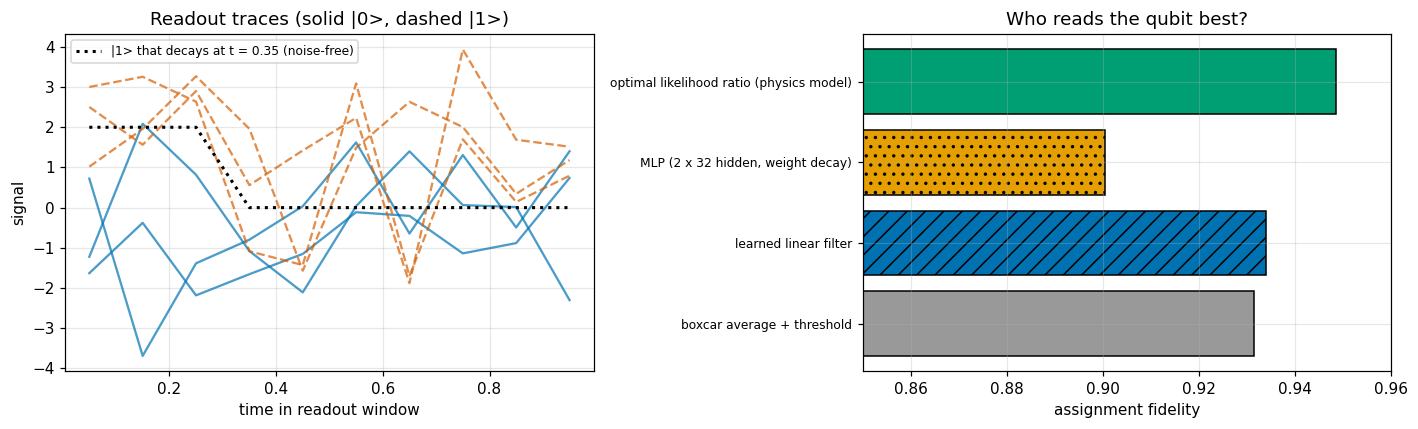

Figure: left, noisy traces; |1> traces sit higher until the qubit decays, and the dotted line shows one that drops early. Right, the physics-based likelihood ratio is the longest bar, the boxcar and learned linear filter are a little shorter, and the neural network is the shortest.


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for idx_, (l_, ls) in enumerate(((0, '-'), (1, '--'))):
    ex = np.where(lab == l_)[0][:3]
    for e in ex:
        ax[0].plot(t_bins, trace[e], ls, alpha=0.7, color=["#0072B2", "#D55E00"][l_])
dec = np.where((lab == 1) & (t_decay < 0.5))[0][0]
ax[0].plot(t_bins, mean_trace[dec], 'k:', lw=2, label='|1> that decays at t = %.2f (noise-free)' % t_decay[dec])
ax[0].set_xlabel('time in readout window'); ax[0].set_ylabel('signal'); ax[0].set_title('Readout traces (solid |0>, dashed |1>)'); ax[0].legend(fontsize=8)
names = list(acc); vals = [acc[n_] for n_ in names]
ax[1].barh(range(len(names)), vals, color=["#999999", "#0072B2", "#E69F00", "#009E73"], hatch=['', '//', '..', ''], edgecolor='k')
ax[1].set_yticks(range(len(names))); ax[1].set_yticklabels(names, fontsize=8); ax[1].set_xlim(0.85, 0.96)
ax[1].set_xlabel('assignment fidelity'); ax[1].set_title('Who reads the qubit best?')
plt.tight_layout(); plt.show()
print('Figure: left, noisy traces; |1> traces sit higher until the qubit decays, and the dotted line shows one that '
      'drops early. Right, the physics-based likelihood ratio is the longest bar, the boxcar and learned linear filter are '
      'a little shorter, and the neural network is the shortest.')

**What this says.** The neural network does *not* win here. With Gaussian noise and a single decay process, the physics already tells you the best possible decision rule: the likelihood ratio that accounts for decay during readout is clearly the best (about 0.95). The boxcar and the learned linear filter are about 1.5 points lower (about 0.93), and a small MLP trained on 4,000 shots is the lowest (about 0.90): it has to learn from data what the physics model states outright. Neural readout pays off in real hardware when the physics model is incomplete (leakage to a third level, crosstalk between qubits, drifting amplifiers, non-Gaussian noise), which is the *Physics-AI Symbiosis* lesson: use the physics model where it is known, and learn only what it misses.

---
## 8. Lean 4: the quantum Hamming bound (§10.3.4)

A non-degenerate code that protects 1 logical qubit with $n$ physical qubits against any single-qubit error needs a distinct syndrome for "no error" and for each of the $3n$ single errors ($X$, $Y$ or $Z$ on any qubit), and each syndrome block holds the 2-dimensional code space:
$$2\,(1 + 3n) \le 2^n$$
Lean checks every $n$ from 1 to 12: it **fails for $n \le 4$**, holds from $n = 5$, and is an **equality at $n = 5$**, which the perfect five-qubit code achieves. Shor's nine-qubit code (§10.2) is comfortably inside the bound. The classical Hamming $[7,4]$ code behind Steane's code (§10.4) is perfect too: $1 + 7 = 2^3$ syndromes.

In [10]:
lean_src = r'''
def hammingOK (n : Nat) : Bool := 2 * (1 + 3 * n) ≤ 2 ^ n
theorem no_code_below_five : [1, 2, 3, 4].all (fun n => !hammingOK n) = true := by decide
theorem bound_from_five : (List.range 8).all (fun i => hammingOK (i + 5)) = true := by decide
theorem five_qubit_code_is_perfect : 2 * (1 + 3 * 5) = 2 ^ 5 := by decide
theorem shor_code_fits : 2 * (1 + 3 * 9) ≤ 2 ^ 9 := by decide
theorem classical_hamming_7_4_perfect : 1 + 7 = 2 ^ 3 := by decide
'''
lean_file = pathlib.Path.cwd() / 'quantum_hamming_bound.lean'
lean_file.write_text(lean_src.strip() + '\n', encoding='utf-8')
print(lean_src.strip())
res = subprocess.run(['lean', '+leanprover/lean4:v4.34.0-rc2', str(lean_file)], capture_output=True, text=True)
print(f'\n{lean_file.name}: {lean_src.count("theorem ")} theorems, exit code {res.returncode}')
print('✓ verified by the Lean kernel' if res.returncode == 0 else (res.stdout + res.stderr))

def hammingOK (n : Nat) : Bool := 2 * (1 + 3 * n) ≤ 2 ^ n
theorem no_code_below_five : [1, 2, 3, 4].all (fun n => !hammingOK n) = true := by decide
theorem bound_from_five : (List.range 8).all (fun i => hammingOK (i + 5)) = true := by decide
theorem five_qubit_code_is_perfect : 2 * (1 + 3 * 5) = 2 ^ 5 := by decide
theorem shor_code_fits : 2 * (1 + 3 * 9) ≤ 2 ^ 9 := by decide
theorem classical_hamming_7_4_perfect : 1 + 7 = 2 ^ 3 := by decide



quantum_hamming_bound.lean: 5 theorems, exit code 0
✓ verified by the Lean kernel


---
## Summary

- **Vectors (§7.2, 7.4):** a dual-rail photon is a 2-vector; beamsplitters and phase shifters are unitary matrices; a Mach-Zehnder interferometer turns phase into output probability.
- **Matrices (§7.3, 7.5):** the harmonic oscillator's equal spacing (all spacings $\hbar\omega$) is why it makes a poor qubit; the Jaynes-Cummings splitting $2\hbar g\sqrt{n+1}$ depends on photon number, which is what makes cavity QED a two-qubit gate.
- **Rates:** gates per coherence time $\tau_Q/\tau_{op}$; logical error rate $\gamma_L \approx 3\gamma^2\Delta t$, so correcting faster helps linearly; concatenation drives error down doubly exponentially below threshold.
- **except:** for qubit readout with Gaussian noise and $T_1$ decay, the physics-based likelihood ratio is the best (about 0.95), linear filters trail by about 1.5 points, and a small neural network is the worst (about 0.90); networks earn their keep when the physics model is incomplete.
- **Lean:** the quantum Hamming bound forbids single-error-correcting codes with fewer than 5 qubits; the 5-qubit code meets it exactly.

## References

[1] M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniversary ed. Cambridge, U.K.: Cambridge Univ. Press, 2010, ch. 7 and ch. 10.

[2] E. T. Jaynes and F. W. Cummings, "Comparison of quantum and semiclassical radiation theories with application to the beam maser," *Proc. IEEE*, vol. 51, no. 1, pp. 89–109, 1963.

[3] P. Krantz *et al.*, "A quantum engineer's guide to superconducting qubits," *Appl. Phys. Rev.*, vol. 6, no. 2, art. 021318, 2019.

[4] R. Laflamme, C. Miquel, J. P. Paz, and W. H. Zurek, "Perfect quantum error correcting code," *Phys. Rev. Lett.*, vol. 77, no. 1, pp. 198–201, 1996.

*Section numbers follow the table of contents you shared; other reference details are from memory: verify before citing.*